# Exercise rejuvenation (aged mouse brain MERFISH): s carries the clock shift, z does not

Old control (4 mice) vs old exercise (4 mice), 594,896 cells x 300 genes (Sun et al. aging/exercise atlas).
Ground truth: the published Spatial Aging Clock applied to observed expression (never seen by Haruka).
Out-of-fold ridge predictions of clock age from z or from s (train 3+3 mice, predict the held-out pair) per
cell type x brain region: s reproduces the observed exercise shift (r = +0.85 across strata, rejuvenation strongest in
vascular cells: VLMC, VSMC, endothelium), z does not (r = -0.17).

In [1]:
import sys; sys.path.insert(0, '/home/yancui/haruka_v2/notebooks')
from repro import run, require, show, STAGES, H, PY
# Default: figure stage only (redraw from saved analysis outputs). Turn on earlier stages to rerun them.
# Fresh machine: STAGES.update(download=True) fetches the preprocessed inputs (section 0), then fit=True, analysis=True.
# STAGES.update(download=True, fit=True, analysis=True)
print(STAGES)

{'download': False, 'data': False, 'fit': False, 'analysis': False, 'figure': True}


## 0 Preprocessed data (Hugging Face)

Skip the data stage: download the ready-to-fit inputs from [C1vy/haruka_v2_data](https://huggingface.co/datasets/C1vy/haruka_v2_data) and link them to the paths the scripts expect.

In [2]:
# C1vy/haruka_v2_data/04_exercise/exercise_old_full.h5ad  ->  /project/zhihuanglab/yancui/haruka_exercise/data/exercise_old_full.h5ad
DL = H / "hf_data"
run(f'hf download C1vy/haruka_v2_data 04_exercise/exercise_old_full.h5ad --repo-type dataset --local-dir {DL} && mkdir -p $(dirname /project/zhihuanglab/yancui/haruka_exercise/data/exercise_old_full.h5ad) && ln -sfn {DL}/04_exercise/exercise_old_full.h5ad /project/zhihuanglab/yancui/haruka_exercise/data/exercise_old_full.h5ad', 'download')

[skip: download stage off] hf download C1vy/haruka_v2_data 04_exercise/exercise_old_full.h5ad --repo-type dataset --local-dir /home/yancui/haruka_v2/hf_data && mkdir -p $(dirname /project/zhihuanglab/yancui/haruka_exercise/data/exercise_old_full.h5ad) && ln -sfn /home/yancui/haruka_v2/hf_data/04_exercise/exercise_old_full.h5ad /project/zhihuanglab/yancui/haruka_exercise/data/exercise_old_full.h5ad


## 1 Data: keep old control / old exercise mice

In [3]:
run(f'{PY} bench_exercise/prepare_exercise.py', 'data')  # /home/yancui/virtualorganoid/exercise.h5ad -> exercise_old_full.h5ad

[skip: data stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_exercise/prepare_exercise.py


## 2 Fit (default model; batch = run; ~15 min on one GPU)

In [4]:
run('bash bench_exercise/run_fit_w10_s100.sh 0', 'fit', log='bench_exercise/logs/fit_w10_s100.log')
require('/project/zhihuanglab/yancui/haruka_exercise/results_w10_s100/exercise_old_full/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0/background.npy', '/project/zhihuanglab/yancui/haruka_exercise/results_w10_s100/exercise_old_full/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0/salient.npy')

[skip: fit stage off] bash bench_exercise/run_fit_w10_s100.sh 0
inputs present


True

## 3 Spatial Aging Clock on observed expression (github sunericd/SpatialAgingClock @ 2b832f4)

In [5]:
run(f'{PY} bench_exercise/run_clock_exercise.py', 'analysis', log='bench_exercise/clock.log')

[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_exercise/run_clock_exercise.py


## 4 Held-out clock prediction from z and s; within-vascular partition; panels
`make_exercise_clock_shift.py` reuses `oof_clock_predictions_w10_s100.csv.gz` if present: move it away for a true rerun.

In [6]:
E = H / 'figures_paper/exercise'
run(f'{PY} make_exercise_clock_shift.py', 'figure', cwd=E)
run(f'{PY} intra_vascular.py', 'analysis', cwd=E)
run(f'{PY} make_intra_panel.py', 'figure', cwd=E)
run(f'{PY} make_exercise_blocks.py', 'figure', cwd=E)
run(f'{PY} ../compose_montage.py exercise_clock && {PY} ../compose_montage.py exercise_blocks', 'figure', cwd=E)

strata 71; observed p<0.05: 10
  all          n= 71 | corr(obs, z) -0.17  corr(obs, s) +0.85 | sign agree z 32%  s 66% | mean shift obs -2.03 z +0.14 s -0.01
  vascular     n= 25 | corr(obs, z) +0.08  corr(obs, s) +0.19 | sign agree z 24%  s 100% | mean shift obs -4.86 z +0.23 s -0.46
  non-vascular n= 46 | corr(obs, z) +0.04  corr(obs, s) +0.75 | sign agree z 37%  s 48% | mean shift obs -0.49 z +0.08 s +0.24
ex_a_observed.svg fonts ok
ex_b_from_z.svg fonts ok
ex_c_from_s.svg fonts ok
ex_d_pred_vs_obs.svg fonts ok
[figure] exit 0 in 6s: /home/yancui/.conda/envs/haruka2/bin/python make_exercise_clock_shift.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python intra_vascular.py


(True, [6.0, 6.5, 8.0])
[figure] exit 0 in 1s: /home/yancui/.conda/envs/haruka2/bin/python make_intra_panel.py


panels: 13 | font failures: []
[figure] exit 0 in 92s: /home/yancui/.conda/envs/haruka2/bin/python make_exercise_blocks.py


wrote /home/yancui/haruka_v2/figures_paper/exercise/Exercise_clock_shift_full.png
wrote /home/yancui/haruka_v2/figures_paper/exercise/Exercise_blocks_full.png
[figure] exit 0 in 4s: /home/yancui/.conda/envs/haruka2/bin/python ../compose_montage.py exercise_clock && /home/yancui/.conda/envs/haruka2/bin/python ../compose_montage.py exercise_blocks


In [7]:
import pandas as pd
d = pd.read_csv(E / 'exercise_clock_shift_by_celltype_region.csv')
print('r(observed, z) = %.2f   r(observed, s) = %.2f' % (d.observed.corr(d.z), d.observed.corr(d.s)))

r(observed, z) = -0.17   r(observed, s) = 0.85


## Figure

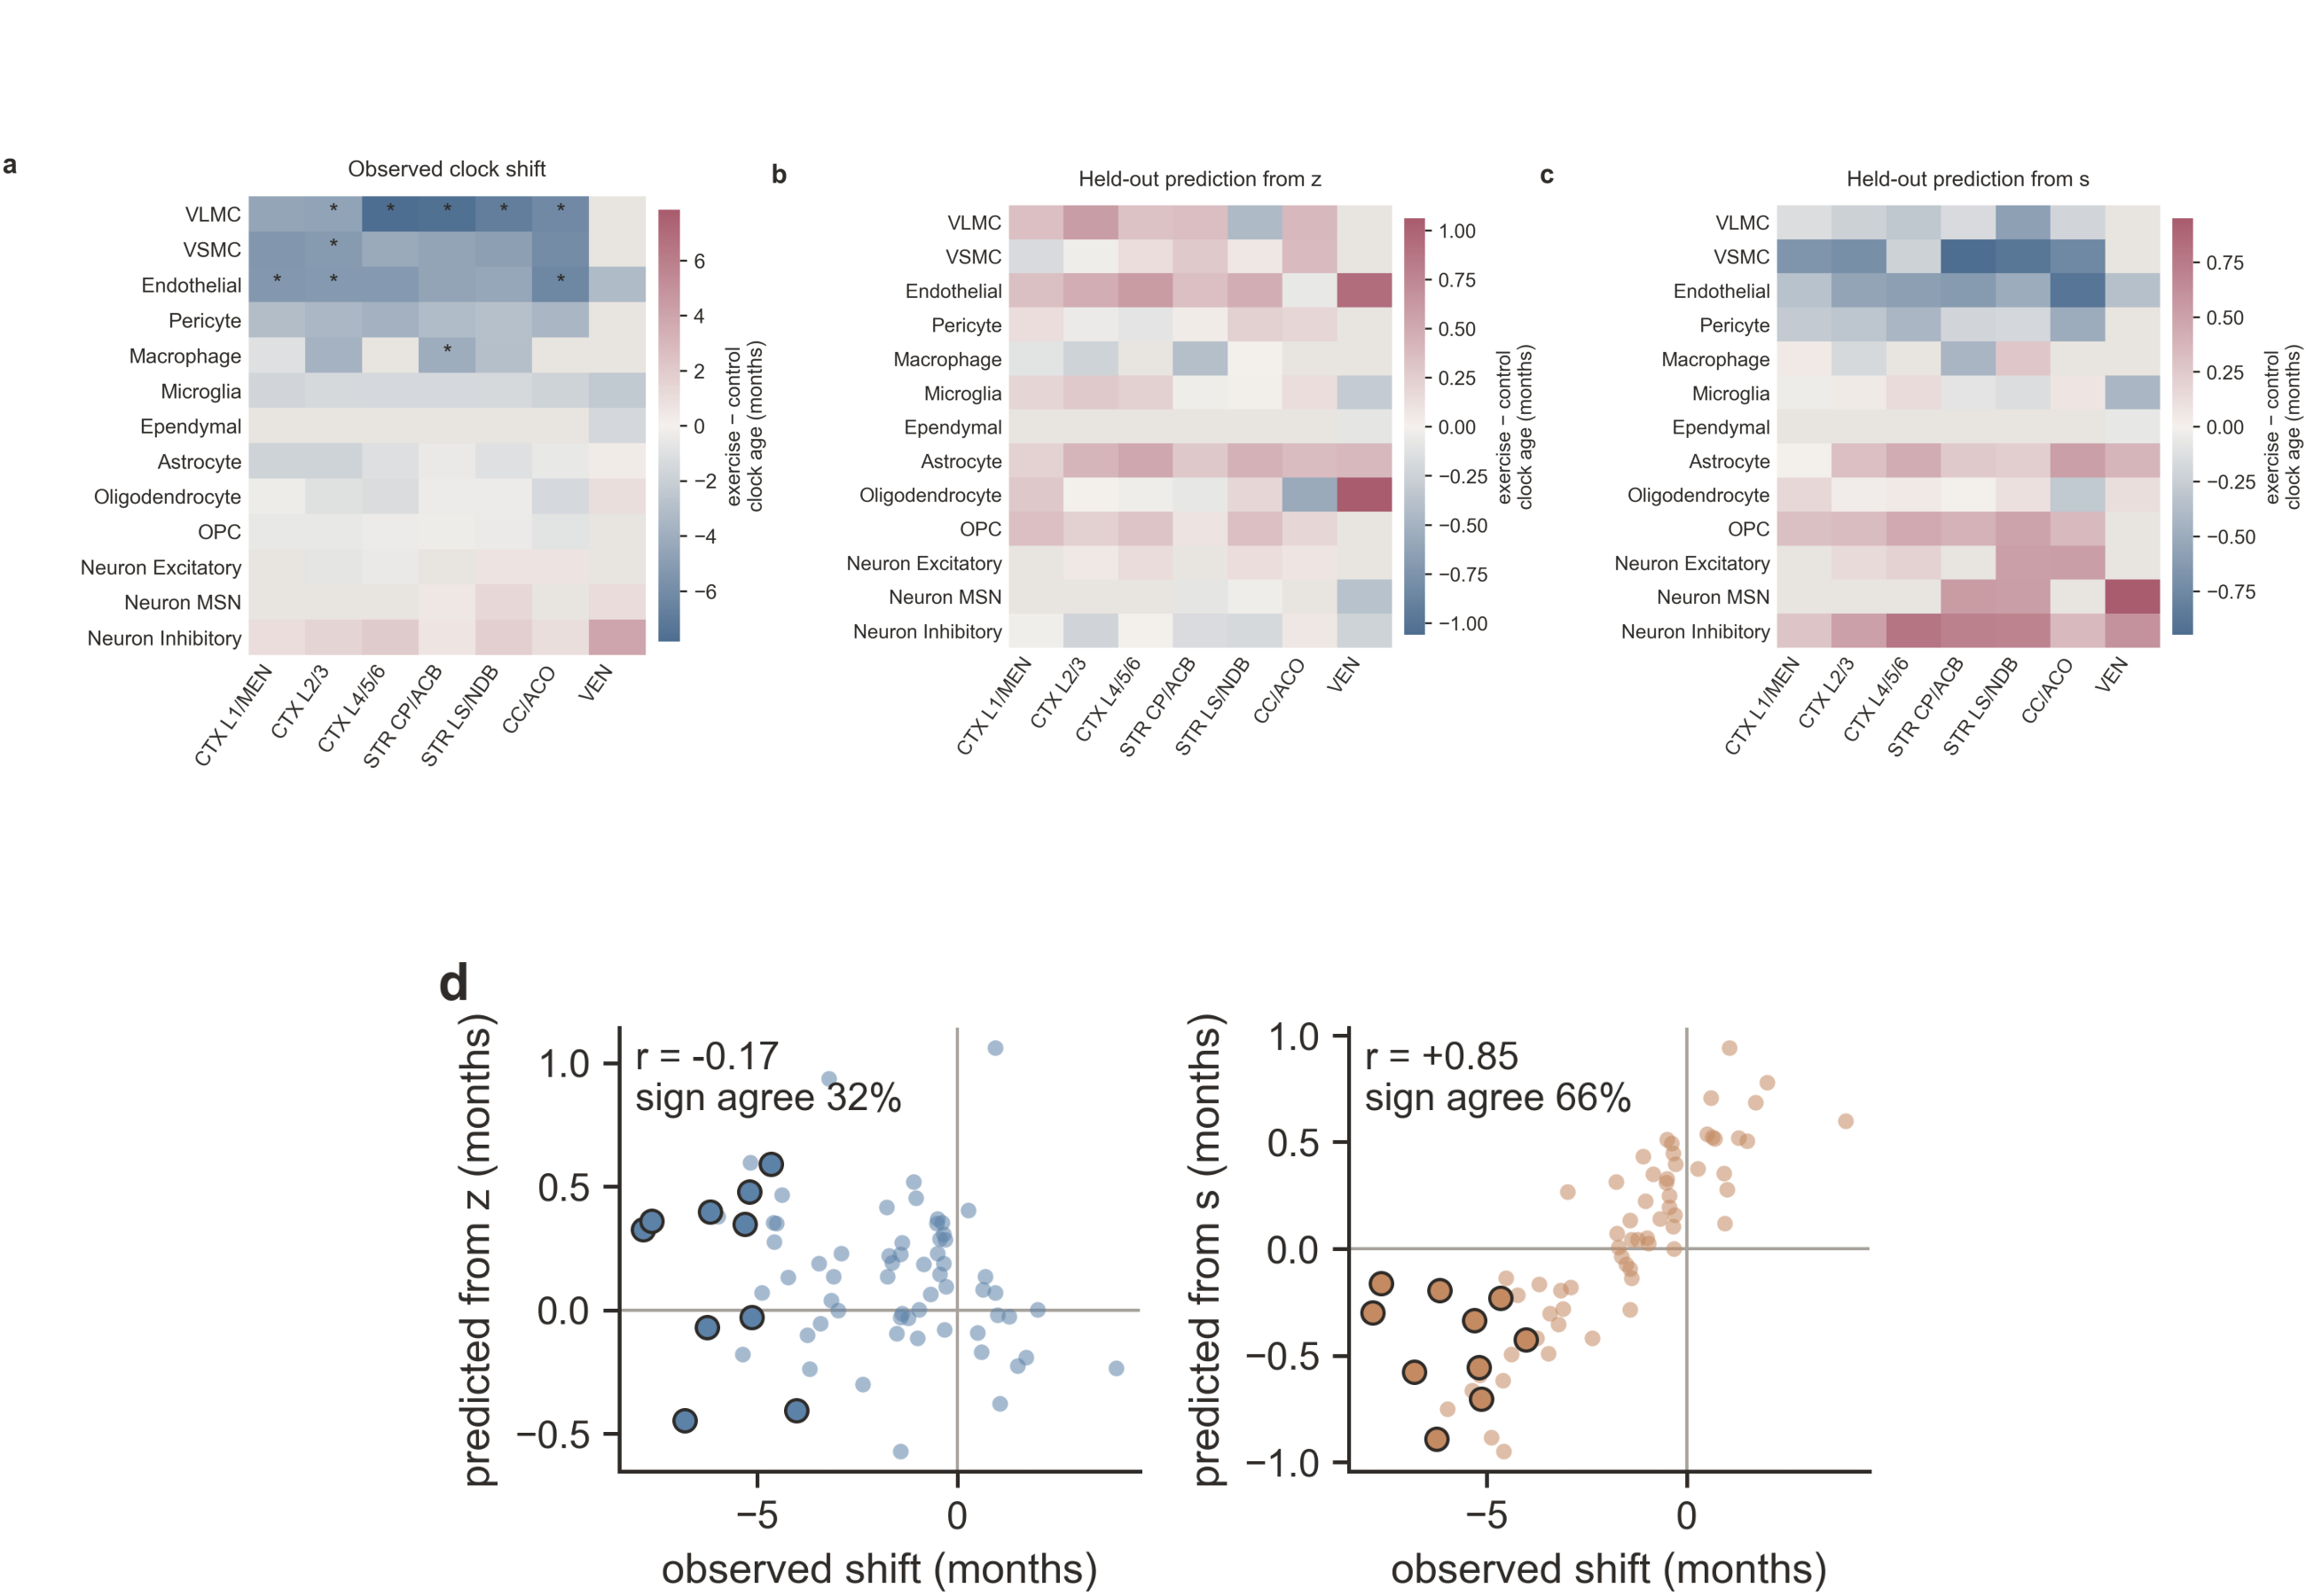

In [8]:
show(H / 'figures_paper/exercise/Exercise_clock_shift_full.png')

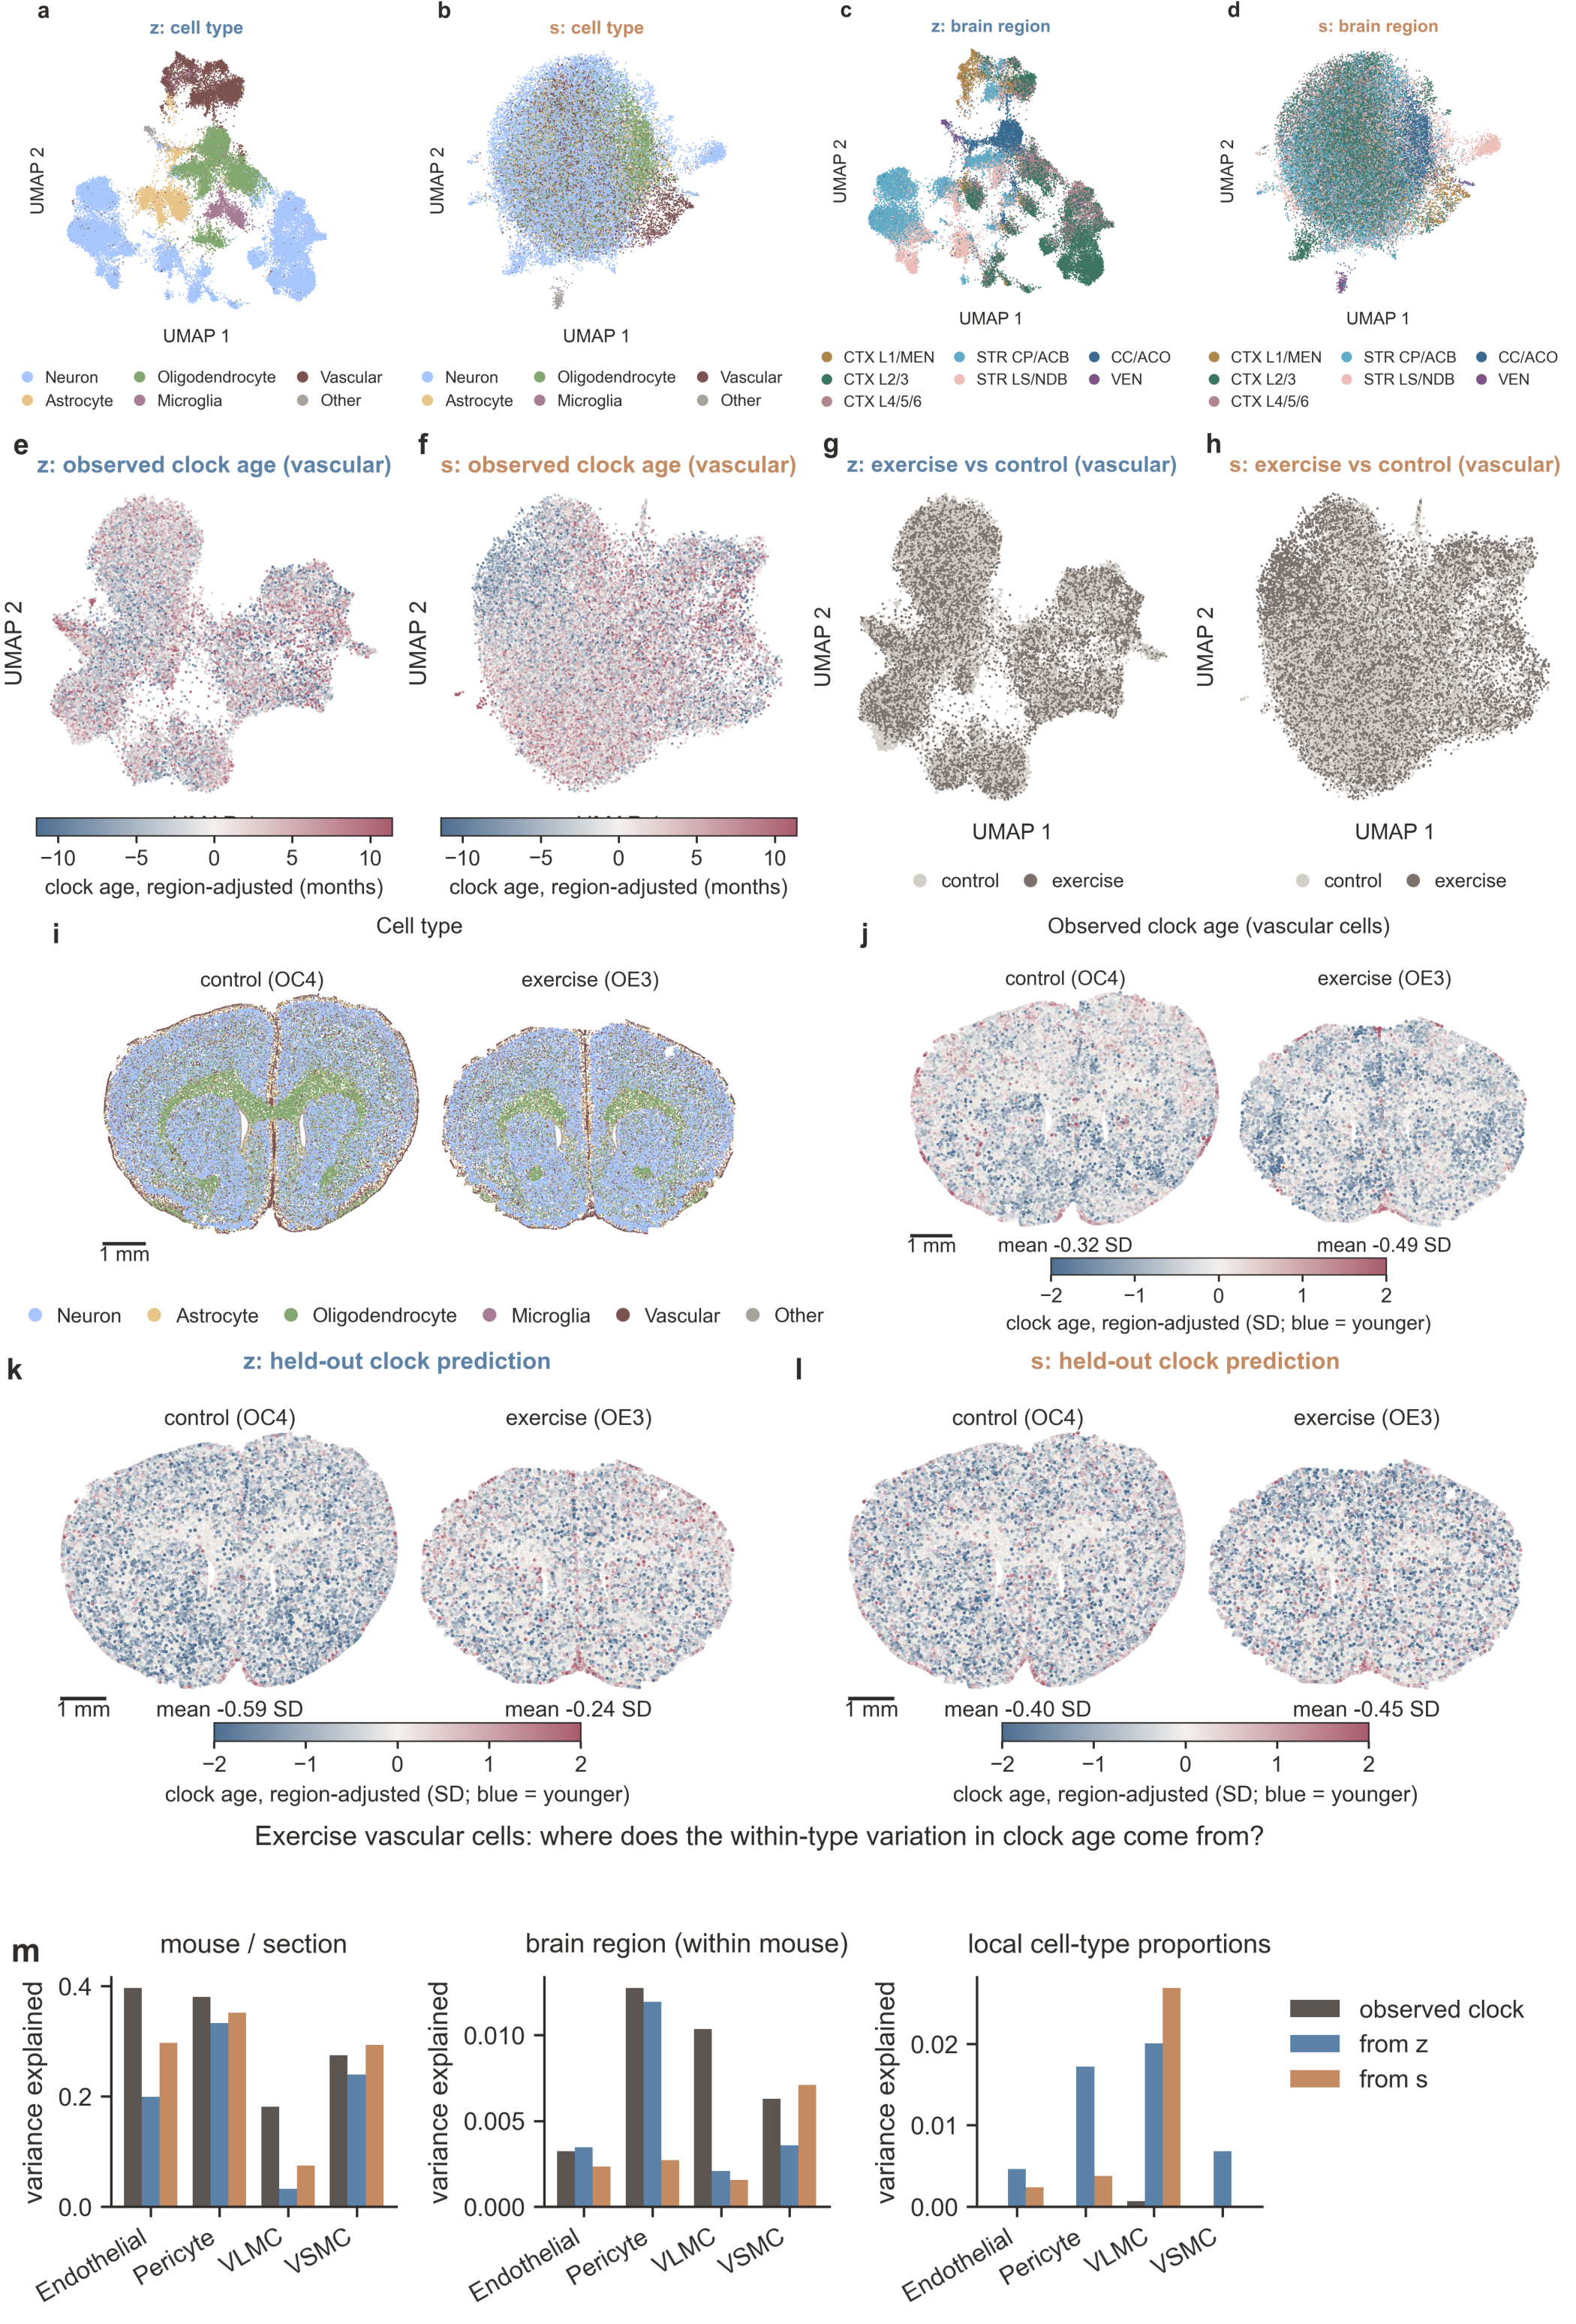

In [9]:
show(H / 'figures_paper/exercise/Exercise_blocks_full.png')